# Thyroid nodule malignancy classification: FibonacciNet vs. a standard CNN

This notebook walks through the full, leakage-safe pipeline and the benchmark results.
All logic lives in `training/` and `utils/`; the notebook only imports and visualises it,
so the scripts and the notebook can never diverge.

| Component | Approach |
|---|---|
| Data | **TN5000** (biopsy-confirmed, Scientific Data 2025) for development; a second public dataset as **external test** |
| Leakage control | Two perceptual hashes, scan-group-safe splits, label-conflict removal, cross-dataset deduplication |
| Class imbalance | Class-weighted loss on the training split |
| Preprocessing | Overlay inpainting, frame crop, aspect-preserving letterbox (identical in training and the app) |
| Augmentation | Ultrasound-specific: gain/TGC, speckle, probe geometry, occlusion |
| Evaluation | AUROC with CIs, calibration, clinical operating points, external test, DeLong, Grad-CAM localization |
| Comparison | FibonacciNet vs a standard CNN, 3 seeds each |

Run from the repository root (`jupyter notebook experiments/THYROID_NODULE_DETECTION.ipynb`).
Training itself runs from the command line (`training/run_benchmark.sh`); this notebook reads its outputs.

In [1]:
import os, sys, json
from pathlib import Path

# Run from the repository root so `training/` and `utils/` import and relative data paths resolve.
if Path.cwd().name == "experiments":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from training.dataset import paths_for, load_cache, tn5000_root, kaggle_root
from training.augment import augment
from utils.processing import prepare_ultrasound

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
COLORS = {"fibonacci_net": "#2a78d6", "baseline_cnn": "#eb6834"}
REPORT = Path("reports/benchmark.json")
report = json.loads(REPORT.read_text()) if REPORT.exists() else None
print("benchmark report:", "found" if report else "not yet generated - run training/run_benchmark.sh")

benchmark report: found


## 1. Data sources

**TN5000** ([Zhang et al., *Scientific Data* 2025](https://doi.org/10.6084/m9.figshare.28455641), CC BY): 5,000 B-mode
images, one radiologist-drawn nodule box each, benign/malignant confirmed by biopsy, official 7:1:2 image-level split.

**Kaggle thyroid ultrasound set**: 3,115 images of undocumented provenance. Used only as an **external test set**: never
for training, calibration, threshold selection or model selection. It shares no images with TN5000 (checked by hashing).

In [2]:
tn_audit = json.loads(paths_for("tn5000")["audit"].read_text())
kg_audit = json.loads(paths_for("kaggle")["audit"].read_text())

rows = [{"set": f"TN5000 {s}", **tn_audit["splits"][s]} for s in ("train", "val", "test")]
ext = tn_audit["external"]
rows.append({"set": "Kaggle external", "n": ext["n"], "benign": ext["benign"], "malignant": ext["malignant"]})
summary = pd.DataFrame(rows).set_index("set")
summary["malignant %"] = (100 * summary.malignant / summary.n).round(1)
summary

,n,benign,malignant,malignant %
set,,,,
TN5000 train,3610,1061,2549,70.6
TN5000 val,461,113,348,75.5
TN5000 test,929,252,677,72.9
Kaggle external,3095,1895,1200,38.8


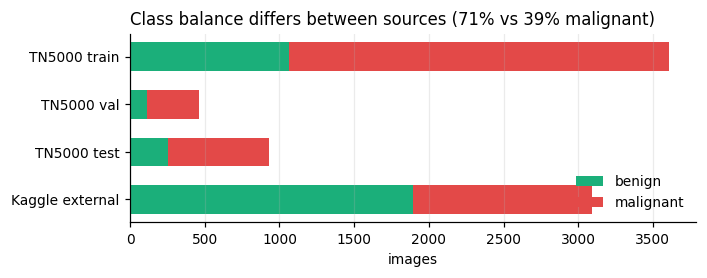

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
y = np.arange(len(summary))
ax.barh(y, summary.benign, color="#1baf7a", label="benign", height=0.6)
ax.barh(y, summary.malignant, left=summary.benign, color="#e34948", label="malignant", height=0.6)
ax.set_yticks(y, summary.index); ax.invert_yaxis(); ax.set_xlabel("images"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Class balance differs between sources (71% vs 39% malignant)", loc="left")
plt.tight_layout()

Malignancy prevalence differs sharply: 71% in TN5000 vs 39% in the Kaggle set. PPV and NPV depend on prevalence,
so the external test also checks how the operating points transfer to a different case mix.

## 2. Duplicates and leakage

Neither dataset has patient IDs. Ultrasound exams produce several near-identical frames per nodule, so an image-level
split puts the same nodule in train and test. We hash every image twice (a 256-bit difference hash and a 255-bit
DCT hash), cluster near-identical images into **scan groups**, and assign whole groups to one split.

In [4]:
pd.DataFrame({
    "TN5000": {
        "near-identical pairs": tn_audit["near_duplicate_pairs"],
        "pairs with contradicting labels": tn_audit["cross_class_duplicate_pairs"],
        "scan groups with >1 image": tn_audit["multi_image_groups"],
        "official VAL images that copy an official TRAIN image": tn_audit["official_split_near_exact_copies_of_train"]["val"],
        "official TEST images that copy an official TRAIN image": tn_audit["official_split_near_exact_copies_of_train"]["test"],
        "images moved into train to make the split group-safe": len(tn_audit["moved_to_train_by_group_check"]),
    },
    "Kaggle": {
        "near-identical pairs": kg_audit["near_duplicate_pairs"],
        "pairs with contradicting labels": kg_audit["cross_class_duplicate_pairs"],
        "scan groups with >1 image": kg_audit["multi_image_groups"],
        "official VAL images that copy an official TRAIN image": "n/a",
        "official TEST images that copy an official TRAIN image": "n/a",
        "images moved into train to make the split group-safe": len(kg_audit["moved_to_train_by_group_check"]),
    },
})

,TN5000,Kaggle
near-identical pairs,146,16
pairs with contradicting labels,0,10
scan groups with >1 image,185,28
official VAL images that copy an official TRAIN image,26,n/a
official TEST images that copy an official TRAIN image,42,n/a
images moved into train to make the split group-safe,110,1


Two findings worth reporting:

* **TN5000's published split leaks.** Dozens of official test images are near-exact copies of official training
  images. We keep the official split but move every split-spanning scan group into train (never out of it), so
  val/test stay strictly unseen.
* **The Kaggle set contains the same image under both labels.** These pairs have no reliable ground truth and are excluded.

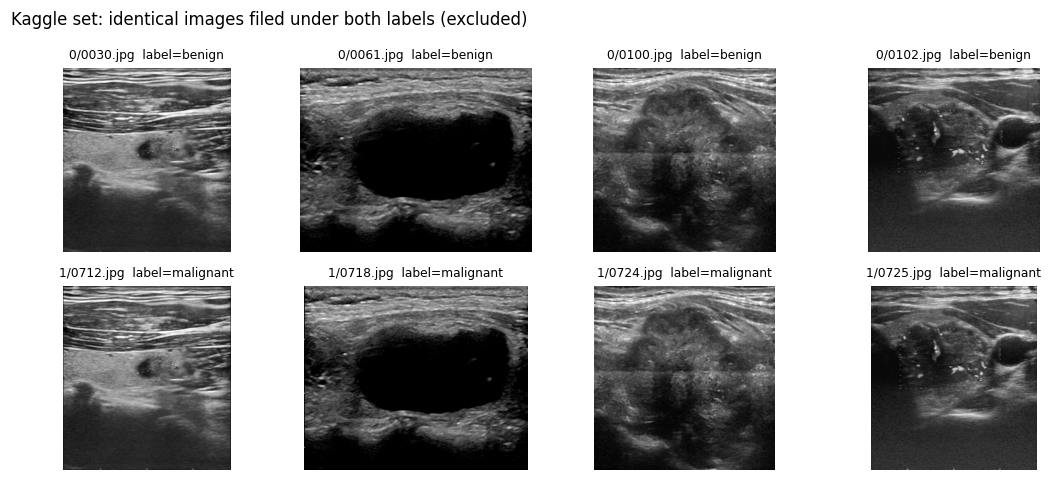

In [5]:
from training.dataset import dhash256, hamming

kg = pd.read_csv(paths_for("kaggle")["splits"])
conf = kg[kg.label_conflict].copy()
conf["hash"] = [dhash256(kaggle_root() / f) for f in conf.file]
pairs, used = [], set()
for i in conf.index:
    for j in conf.index:
        if i < j and i not in used and j not in used and conf.label[i] != conf.label[j] \
                and hamming(conf.hash[i][None], conf.hash[j][None])[0, 0] <= 30:
            pairs.append((conf.file[i], conf.file[j])); used |= {i, j}

fig, axes = plt.subplots(2, 4, figsize=(10, 4.4))
for k, (a, b) in enumerate(pairs[:4]):
    for r, f in enumerate((a, b)):
        ax = axes[r, k]
        ax.imshow(Image.open(kaggle_root() / f), cmap="gray"); ax.axis("off")
        ax.set_title(f"{f}  label={'malignant' if f.startswith('1') else 'benign'}", fontsize=8)
fig.suptitle("Kaggle set: identical images filed under both labels (excluded)", x=0.01, ha="left")
plt.tight_layout()

42 official test images have a near-exact copy in the official training split


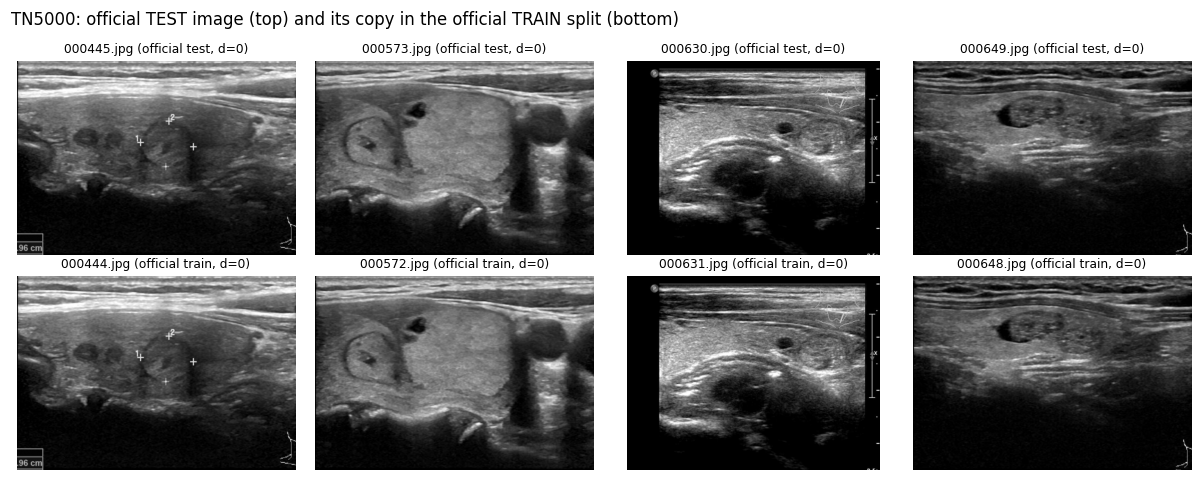

In [6]:
from training.dataset import index_tn5000, phash255

# Official TN5000 test images that are near-exact copies of an official training image.
tn_index = index_tn5000(tn5000_root())
codes = np.stack([dhash256(p) for p in tn_index.path])
dist = hamming(codes, codes)
np.fill_diagonal(dist, 999)
test_idx = np.where(tn_index.official_split == "test")[0]
train_idx = np.where(tn_index.official_split == "train")[0]
leaks = [(i, train_idx[np.argmin(dist[i, train_idx])]) for i in test_idx if dist[i, train_idx].min() <= 30]
print(f"{len(leaks)} official test images have a near-exact copy in the official training split")

fig, axes = plt.subplots(2, 4, figsize=(11, 4.4))
for k, (i, j) in enumerate(leaks[:4]):
    for r, idx in enumerate((i, j)):
        ax = axes[r, k]
        ax.imshow(Image.open(tn_index.path[idx]).convert("L"), cmap="gray"); ax.axis("off")
        ax.set_title(f"{tn_index.file[idx]} (official {tn_index.official_split[idx]}, d={dist[i, j]})", fontsize=8)
fig.suptitle("TN5000: official TEST image (top) and its copy in the official TRAIN split (bottom)", x=0.01, ha="left")
plt.tight_layout()

A second, independent hash (DCT-based, sensitive to low-frequency content rather than gradients) is combined with the
difference hash when forming scan groups. On the Kaggle set it caught one extra cross-split pair of adjacent frames
that the difference hash alone had missed; on TN5000 the combined grouping drives the split corrections above.

Imbalance is handled on the training split only, with a **class-weighted loss**. No image is duplicated, so
nothing can leak from train into evaluation through resampling:

In [7]:
data = load_cache("tn5000")
ytr = data["train"][1]
pos = ytr.mean()
print(f"train prevalence {pos:.3f} -> class weights: benign {0.5 / (1 - pos):.2f}, malignant {0.5 / pos:.2f}")

train prevalence 0.706 -> class weights: benign 1.70, malignant 0.71


## 3. Preprocessing (shared by training and the app)

`utils/processing.prepare_ultrasound` is the single preprocessing function used by training, evaluation and the web app:

1. **Coloured overlay inpainting.** B-mode ultrasound is grayscale, so any saturated pixel is burned-in text or a
   marker, never tissue. These pixels are inpainted. Brightness-based removal is deliberately avoided because bright
   echogenic foci (microcalcifications) are a key TI-RADS malignancy feature.
2. **Frame crop.** Removes the black scanner border.
3. **Letterbox to 224x224.** Preserves aspect ratio. A plain stretch distorts nodule shape, and
   *taller-than-wide* is itself a TI-RADS malignancy criterion.

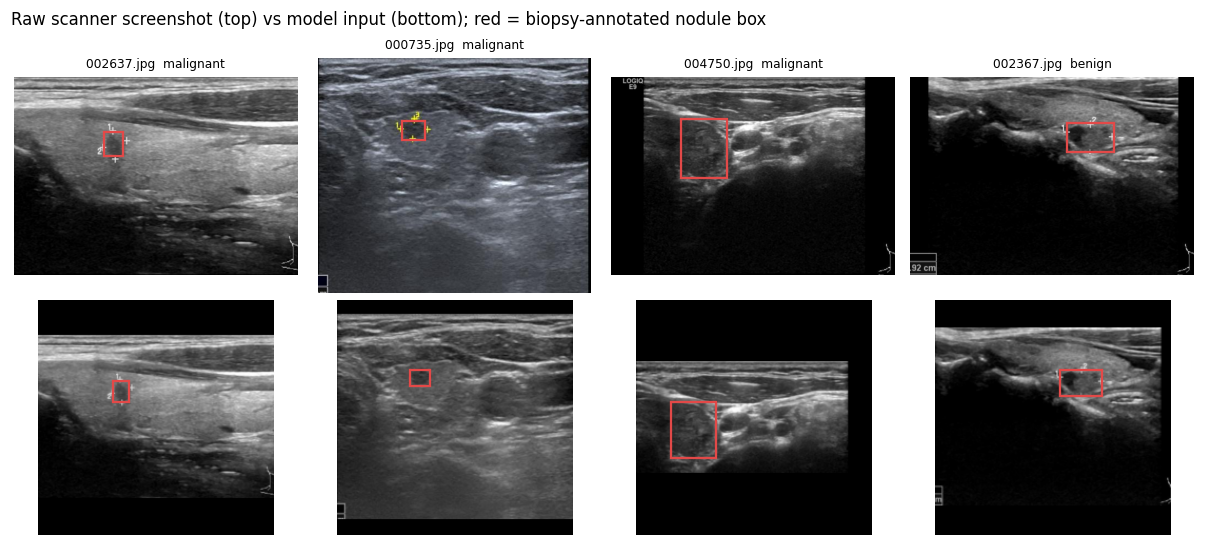

In [8]:
tn = pd.read_csv(paths_for("tn5000")["splits"])
tn = tn[~tn.file.str.startswith("kaggle/")]
examples = tn[tn.split == "test"].sample(4, random_state=3)

fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for k, row in enumerate(examples.itertuples()):
    img = Image.open(tn5000_root() / "JPEGImages" / row.file)
    axes[0, k].imshow(img); axes[0, k].axis("off")
    axes[0, k].add_patch(plt.Rectangle((row.xmin, row.ymin), row.xmax - row.xmin, row.ymax - row.ymin,
                                       fill=False, ec="#e34948", lw=1.5))
    axes[0, k].set_title(f"{row.file}  {'malignant' if row.label else 'benign'}", fontsize=8)
    out, to_frame = prepare_ultrasound(img, return_transform=True)
    (x0, y0), (x1, y1) = to_frame(row.xmin, row.ymin), to_frame(row.xmax, row.ymax)
    axes[1, k].imshow(out, cmap="gray", vmin=0, vmax=255); axes[1, k].axis("off")
    axes[1, k].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="#e34948", lw=1.5))
axes[0, 0].set_ylabel("raw"); axes[1, 0].set_ylabel("model input")
fig.suptitle("Raw scanner screenshot (top) vs model input (bottom); red = biopsy-annotated nodule box",
             x=0.01, ha="left")
plt.tight_layout()

**Why not also remove white calipers by brightness?** A natural idea is to detect small, bright, thin structures and
inpaint them too. Below, a white top-hat filter with a near-saturation threshold, the usual heuristic, is applied
to test images. It fails in both directions. It **misses most calipers** (the white "+" marks are mid-grey after
resizing and stay unflagged), and it **flags bright tissue** (red): capsule edges, strong reflectors, and in
other images echogenic foci. Echogenic foci, including microcalcifications, are among the strongest TI-RADS
malignancy signs, so this step would delete real diagnostic signal while leaving the calipers in place. Calipers are left in place, and their influence is measured with the Grad-CAM
localization test instead (section 8).

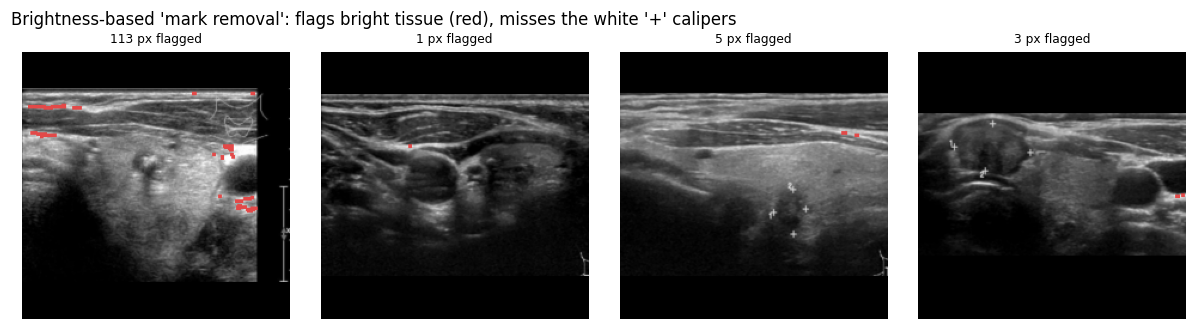

In [9]:
import cv2
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, i in zip(axes, np.random.RandomState(0).choice(len(data["test"][0]), 4, replace=False)):
    g = data["test"][0][i]
    tophat = cv2.morphologyEx(g, cv2.MORPH_TOPHAT, np.ones((7, 7), np.uint8))
    flagged = (g >= 235) & (tophat >= 60)
    rgb = np.stack([g] * 3, -1).copy()
    rgb[cv2.dilate(flagged.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0] = [227, 73, 72]
    ax.imshow(rgb); ax.axis("off"); ax.set_title(f"{flagged.sum()} px flagged", fontsize=8)
fig.suptitle("Brightness-based 'mark removal': flags bright tissue (red), misses the white '+' calipers", x=0.01, ha="left")
plt.tight_layout()

## 4. Ultrasound-specific augmentation (train split only)

| Transform | Real-world source of variability |
|---|---|
| Horizontal flip | Left/right lobe, probe orientation |
| ±10° rotation, zoom, translation | Probe angle, depth setting, footprint |
| Gain / contrast / gamma | Operator gain and TGC settings |
| Multiplicative speckle noise | Ultrasound speckle |
| Random erasing | Occlusion; weakens reliance on burned-in calipers |

No vertical flip: depth is anatomically meaningful (skin at the top, acoustic shadowing below).

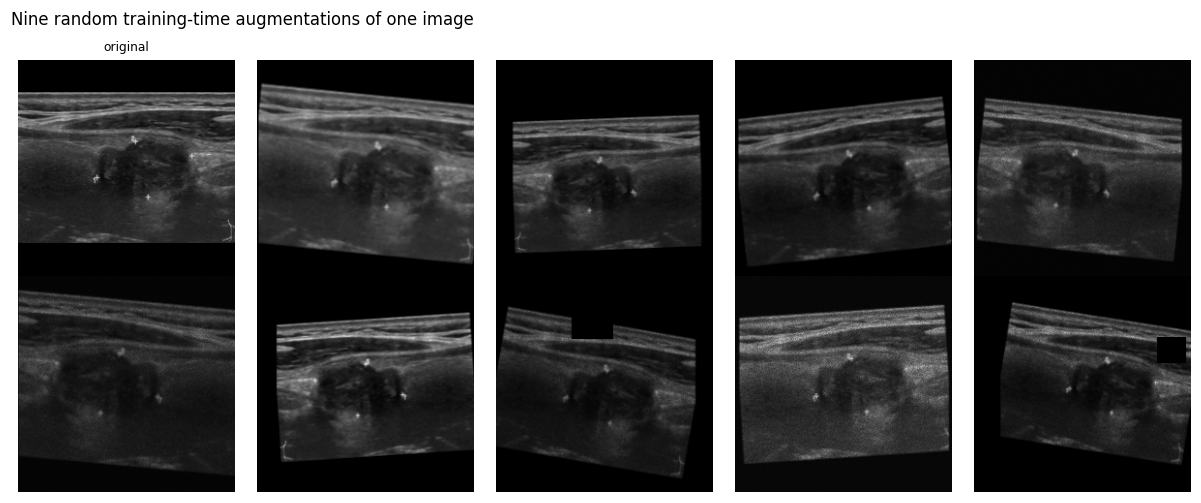

In [10]:
import tensorflow as tf
tf.keras.utils.set_random_seed(0)
src = data["train"][0][7].astype(np.float32)[..., None] / 255.0
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
axes[0, 0].imshow(src[..., 0], cmap="gray", vmin=0, vmax=1); axes[0, 0].set_title("original", fontsize=8)
for ax in axes.flat[1:]:
    ax.imshow(augment(tf.constant(src)).numpy()[..., 0], cmap="gray", vmin=0, vmax=1)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Nine random training-time augmentations of one image", x=0.01, ha="left")
plt.tight_layout()

In [11]:
from training.augment import STRENGTHS
pd.DataFrame(STRENGTHS, index=["gain ±", "contrast ±", "log-gamma ±", "max speckle σ", "random-erase prob."]).T \
    .rename_axis("strength").assign(**{"rotation": "±10°", "zoom": "−10% / +15%", "translation": "±8%",
                                       "h-flip": "50%"})

,gain ±,contrast ±,log-gamma ±,max speckle σ,random-erase prob.,rotation,zoom,translation,h-flip
strength,,,,,,,,,
standard,0.2,0.25,0.25,0.12,0.30,±10°,−10% / +15%,±8%,50%
light,0.1,0.12,0.12,0.06,0.15,±10°,−10% / +15%,±8%,50%


"standard" is the selected setting; "light" scored slightly lower on validation in the recipe sweep (section 6).

## 5. Architectures

Both share the input, global-average-pooling head and training recipe. Only the feature extractor differs.

* **FibonacciNet**: 21-34-55-89-144 conv blocks, depthwise-separable 233/377 tail, two parallel concatenation
  blocks (pcb) whose pooling is *Avg-2Max* (`avg − 2·max`, an edge-emphasising pooling).
* **Standard CNN**: same depth, power-of-two widths (32…512), standard 3x3 tail, max pooling, no branches.

In [12]:
from utils.model_architecture import MODEL_BUILDERS
pd.DataFrame([{"model": name, "parameters": MODEL_BUILDERS[name](input_shape=(224, 224, 3)).count_params()}
              for name in ("fibonacci_net", "baseline_cnn")]).set_index("model")

,parameters
model,
fibonacci_net,380152
baseline_cnn,6296769


## 6. Training recipe selection (no tuning on TN5000)

The recipe was chosen on the **Kaggle validation split only** and then frozen. TN5000 therefore received zero
hyperparameter tuning, which removes selection bias from the headline numbers. The 60-epoch Kaggle budget
(~3,700 optimizer steps) maps to 40 epochs on TN5000's larger training split (~4,500 steps).

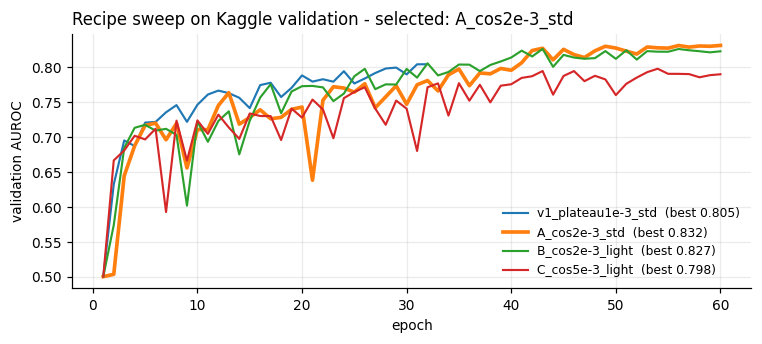

In [13]:
sweep = json.loads(Path("reports/sweep.json").read_text())
fig, ax = plt.subplots(figsize=(7, 3.2))
for r in sweep["runs"]:
    lw = 2.4 if r["name"] == sweep["selected"] else 1.4
    ax.plot(np.arange(1, len(r["val_auc_curve"]) + 1), r["val_auc_curve"], lw=lw,
            label=f"{r['name']}  (best {r['best_val_auc']:.3f})")
ax.set_xlabel("epoch"); ax.set_ylabel("validation AUROC")
ax.set_title(f"Recipe sweep on Kaggle validation - selected: {sweep['selected']}", loc="left")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

## 7. Benchmark results

Everything below is read from `reports/benchmark.json`. Calibration (Platt scaling) and the two operating
points are fitted on validation and then frozen for test **and** for the external set.

In [14]:
def fmt(s, pct=False):
    f = (lambda v: f"{100 * v:.1f}") if pct else (lambda v: f"{v:.3f}")
    return f"{f(s['mean'])} ± {f(s['sd'])}"

if report:
    rows = []
    for name, m in report["models"].items():
        s, e = m["summary"], m["efficiency"]
        rows.append({
            "model": m["display"], "seeds": m["n_seeds"],
            "TN5000 AUROC": fmt(s["auc"]), "external AUROC": fmt(s["external_auc"]) if "external_auc" in s else "-",
            "sens @ rule-out %": fmt(s["rule_out_sensitivity"], True),
            "spec @ rule-out %": fmt(s["rule_out_specificity"], True),
            "Brier": fmt(s["brier"]), "params": f"{e['params'] / 1e6:.2f} M",
            "GFLOPs": f"{e['flops'] / 1e9:.2f}", "CPU ms": e["latency_ms_cpu"],
            "Grad-CAM hit %": f"{100 * m['localization']['hit_rate']:.1f}",
        })
    display(pd.DataFrame(rows).set_index("model"))

,seeds,TN5000 AUROC,external AUROC,sens @ rule-out %,spec @ rule-out %,Brier,params,GFLOPs,CPU ms,Grad-CAM hit %
model,,,,,,,,,,
FibonacciNet,3,0.894 ± 0.008,0.763 ± 0.012,88.9 ± 0.6,72.8 ± 2.4,0.110 ± 0.005,0.38 M,0.76,4.18,23.3
Standard CNN baseline,3,0.901 ± 0.011,0.771 ± 0.014,90.0 ± 1.4,73.8 ± 2.4,0.106 ± 0.006,6.30 M,2.40,8.50,33.8


In [15]:
if report and report.get("comparison"):
    c = report["comparison"]
    lines = []
    for label, key in (("TN5000 test", "seed_averaged"), ("External (Kaggle)", "external_seed_averaged")):
        r = c.get(key)
        if r:
            lines.append({"test set": label, "ΔAUROC (Fib − CNN)": round(r["diff"], 4),
                          "95% CI": f"[{r['diff_ci95'][0]:.3f}, {r['diff_ci95'][1]:.3f}]",
                          "DeLong p": f"{r['p_value']:.3g}",
                          f"non-inferior (margin {c['non_inferiority_margin']})": r["diff_ci95"][0] > -c["non_inferiority_margin"]})
    display(pd.DataFrame(lines).set_index("test set"))
    print(f"FibonacciNet uses {c['param_reduction_x']}x fewer parameters, {c['flop_reduction_x']}x fewer FLOPs, "
          f"and runs {c['latency_speedup_x']}x faster on CPU than the standard CNN.")

,ΔAUROC (Fib − CNN),95% CI,DeLong p,non-inferior (margin 0.03)
test set,,,,
TN5000 test,-0.0020,"[-0.016, 0.011]",0.775,True
External (Kaggle),-0.0018,"[-0.011, 0.008]",0.727,True


FibonacciNet uses 16.6x fewer parameters, 3.1x fewer FLOPs, and runs 2.0x faster on CPU than the standard CNN.


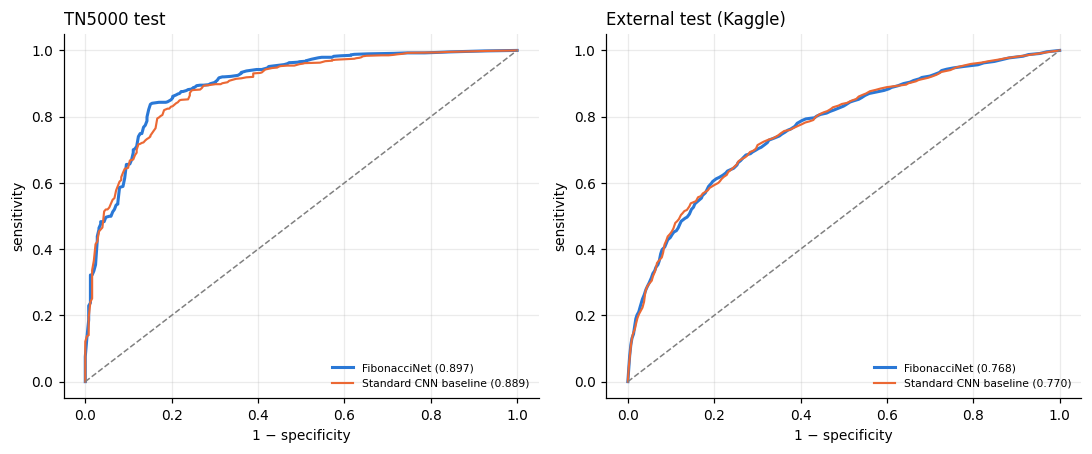

In [16]:
if report:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, key, title in ((axes[0], None, "TN5000 test"), (axes[1], "external", "External test (Kaggle)")):
        for name, m in report["models"].items():
            sel = m["selected"] if key is None else m["selected"].get("external")
            if not sel:
                continue
            ax.plot(sel["roc"]["fpr"], sel["roc"]["tpr"], color=COLORS[name], lw=2 if name == "fibonacci_net" else 1.4,
                    label=f"{m['display']} ({sel['auc']:.3f})")
        ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
        ax.set_xlabel("1 − specificity"); ax.set_ylabel("sensitivity"); ax.set_title(title, loc="left")
        ax.legend(frameon=False, fontsize=7, loc="lower right")
    plt.tight_layout()

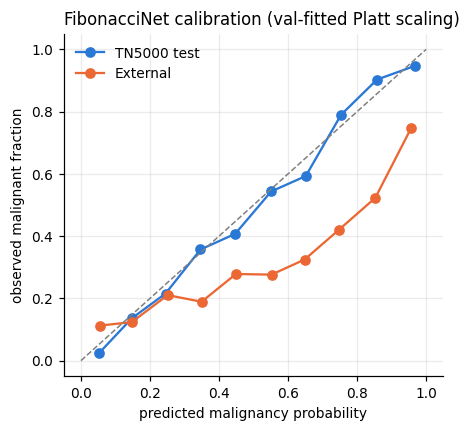

In [17]:
if report and "fibonacci_net" in report["models"]:
    sel = report["models"]["fibonacci_net"]["selected"]
    fig, ax = plt.subplots(figsize=(4.2, 4))
    for bins, label, col in ((sel["calibration_bins"], "TN5000 test", "#2a78d6"),
                             ((sel.get("external") or {}).get("calibration_bins"), "External", "#eb6834")):
        if bins:
            ax.plot([b["pred"] for b in bins], [b["obs"] for b in bins], "o-", color=col, label=label)
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
    ax.set_xlabel("predicted malignancy probability"); ax.set_ylabel("observed malignant fraction")
    ax.set_title("FibonacciNet calibration (val-fitted Platt scaling)", loc="left"); ax.legend(frameon=False)
    plt.tight_layout()

In [18]:
if report and "fibonacci_net" in report["models"]:
    sel = report["models"]["fibonacci_net"]["selected"]
    ops = []
    for setname, src in (("TN5000 test", sel), ("External", sel.get("external"))):
        if not src:
            continue
        for op in ("rule_out", "rule_in", "balanced"):
            r = src[op]
            ops.append({"set": setname, "operating point": op, "threshold": round(r["threshold"], 3),
                        "sensitivity": round(r["sensitivity"], 3), "specificity": round(r["specificity"], 3),
                        "PPV": round(r["ppv"], 3), "NPV": round(r["npv"], 3), "missed cancers (FN)": r["fn"]})
    display(pd.DataFrame(ops).set_index(["set", "operating point"]))

threshold  sensitivity  specificity    PPV  \
set         operating point                                               
TN5000 test rule_out             0.634        0.885        0.754  0.906   
            rule_in              0.835        0.737        0.877  0.942   
            balanced             0.617        0.892        0.742  0.903   
External    rule_out             0.634        0.732        0.668  0.583   
            rule_in              0.835        0.533        0.847  0.688   
            balanced             0.617        0.743        0.649  0.573   

                               NPV  missed cancers (FN)  
set         operating point                              
TN5000 test rule_out         0.709                   78  
            rule_in          0.554                  178  
            balanced         0.719                   73  
External    rule_out         0.797                  322  
            rule_in          0.741                  560  
            balanced         0.799                  309

### Per-seed results and training curves

Every run is trained for the full 40-epoch budget; the weights from the epoch with the best **validation** AUROC are
kept. The table lists every seed so the spread is visible, not only the mean.

In [19]:
if report:
    per_seed = []
    for name, m in report["models"].items():
        for r in m["runs"]:
            per_seed.append({"model": m["display"], "seed": r["seed"], "val AUROC": round(r["val_auc"], 4),
                             "TN5000 test AUROC": round(r["auc"], 4), "epochs": r["epochs_run"],
                             "selected for deployment": r["seed"] == m["selected_seed"]})
    display(pd.DataFrame(per_seed).set_index(["model", "seed"]))

val AUROC  TN5000 test AUROC  epochs  \
model                 seed                                         
FibonacciNet          0        0.9065             0.8972      40   
                      1        0.9031             0.8988      40   
                      2        0.8995             0.8846      40   
Standard CNN baseline 0        0.9139             0.9077      40   
                      1        0.9170             0.8888      40   
                      2        0.9158             0.9068      40   

                            selected for deployment  
model                 seed                           
FibonacciNet          0                        True  
                      1                       False  
                      2                       False  
Standard CNN baseline 0                       False  
                      1                        True  
                      2                       False

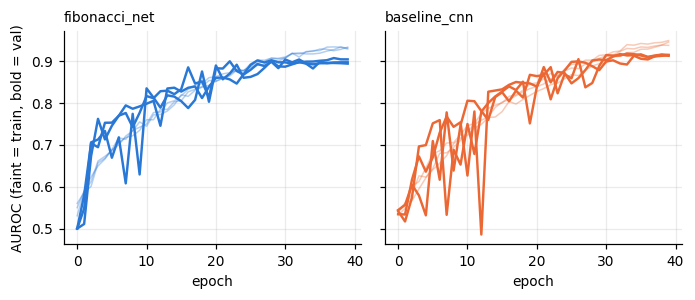

In [20]:
runs_dir = Path("reports/runs")
if runs_dir.exists():
    names = [n for n in COLORS if (runs_dir / n).exists()]
    fig, axes = plt.subplots(1, len(names), figsize=(3.2 * len(names), 2.8), sharey=True, squeeze=False)
    for ax, name in zip(axes[0], names):
        for h in sorted((runs_dir / name).glob("seed*/history.json")):
            hist = json.loads(h.read_text())["history"]
            ax.plot(hist["auc"], color=COLORS[name], alpha=0.35, lw=1)
            ax.plot(hist["val_auc"], color=COLORS[name], lw=1.6)
        ax.set_title(name, fontsize=9, loc="left"); ax.set_xlabel("epoch")
    axes[0, 0].set_ylabel("AUROC (faint = train, bold = val)")
    plt.tight_layout()

In [21]:
if report:
    display(pd.DataFrame({m["display"]: m["efficiency"] for m in report["models"].values()}).T
            .rename(columns={"params": "parameters", "flops": "FLOPs", "size_mb": "file size (MB)",
                             "latency_ms_cpu": "CPU latency (ms, batch 1)"}))

,parameters,FLOPs,file size (MB),"CPU latency (ms, batch 1)"
FibonacciNet,380152.0,7.623578e+08,4.74,4.18
Standard CNN baseline,6296769.0,2.398815e+09,75.66,8.50


## 8. Does the model look at the nodule?

Grad-CAM "pointing game" against the radiologist-drawn nodule boxes on the TN5000 test set. *Hit rate* is the
share of images whose heatmap peak falls inside the nodule box. *Energy in box* is the share of heatmap mass inside
the box, compared with the box's share of the image (what an uninformative, uniform heatmap would score).

In [22]:
if report:
    loc = pd.DataFrame({m["display"]: m["localization"] for m in report["models"].values()}).T
    loc["energy lift vs uniform"] = (loc.energy_in_box / loc.box_area_fraction).round(2)
    display(loc[["hit_rate", "energy_in_box", "box_area_fraction", "energy lift vs uniform"]].round(3))

,hit_rate,energy_in_box,box_area_fraction,energy lift vs uniform
FibonacciNet,0.233,0.114,0.054,2.11
Standard CNN baseline,0.338,0.108,0.054,2.00


/Users/divyanshagarwal/Desktop/projects/healthcare/thyroid-nodule-detection/mac_env/lib/python3.13/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


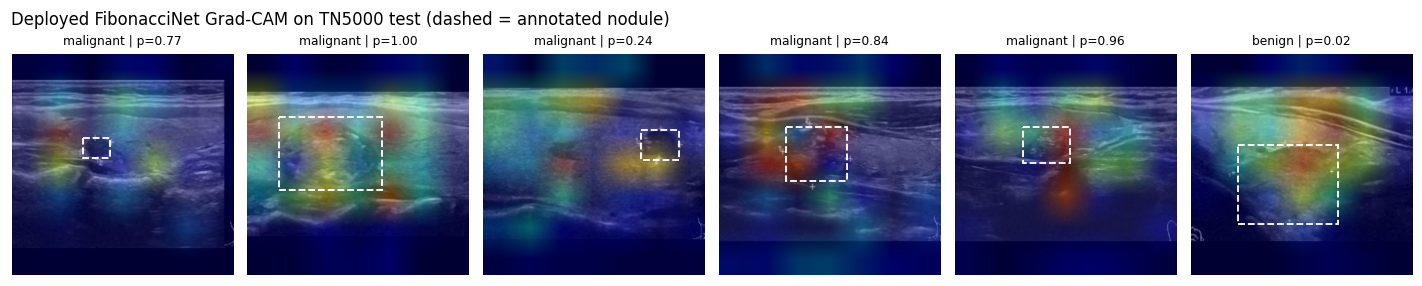

In [23]:
model_path = Path("models/fibonacci_net.keras")
if model_path.exists():
    from utils.model_architecture import CUSTOM_OBJECTS
    from utils.gradcam import find_target_layer, make_gradcam_heatmap, save_and_display_gradcam
    model = tf.keras.models.load_model(model_path, custom_objects=CUSTOM_OBJECTS, compile=False)
    xte, yte, fte = data["test"]; boxes = data["test_boxes"]
    idx = np.random.RandomState(1).choice(len(xte), 6, replace=False)
    fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
    for ax, i in zip(axes, idx):
        batch = np.repeat(xte[i][None, ..., None].astype(np.float32) / 255.0, 3, axis=-1)
        p = float(model(batch, training=False)[0, 0])
        heat = make_gradcam_heatmap(batch, model, find_target_layer(model))
        ax.imshow(save_and_display_gradcam(xte[i], heat)); ax.axis("off")
        x0, y0, x1, y1 = boxes[i]
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="white", lw=1.2, ls="--"))
        ax.set_title(f"{'malignant' if yte[i] else 'benign'} | p={p:.2f}", fontsize=8)
    fig.suptitle("Deployed FibonacciNet Grad-CAM on TN5000 test (dashed = annotated nodule)", x=0.01, ha="left")
    plt.tight_layout()

## 9. Error analysis

The deployed model's most confident mistakes on the TN5000 test set, at the rule-out threshold. Missed cancers
(false negatives) are the clinically costly error and deserve the closest look.

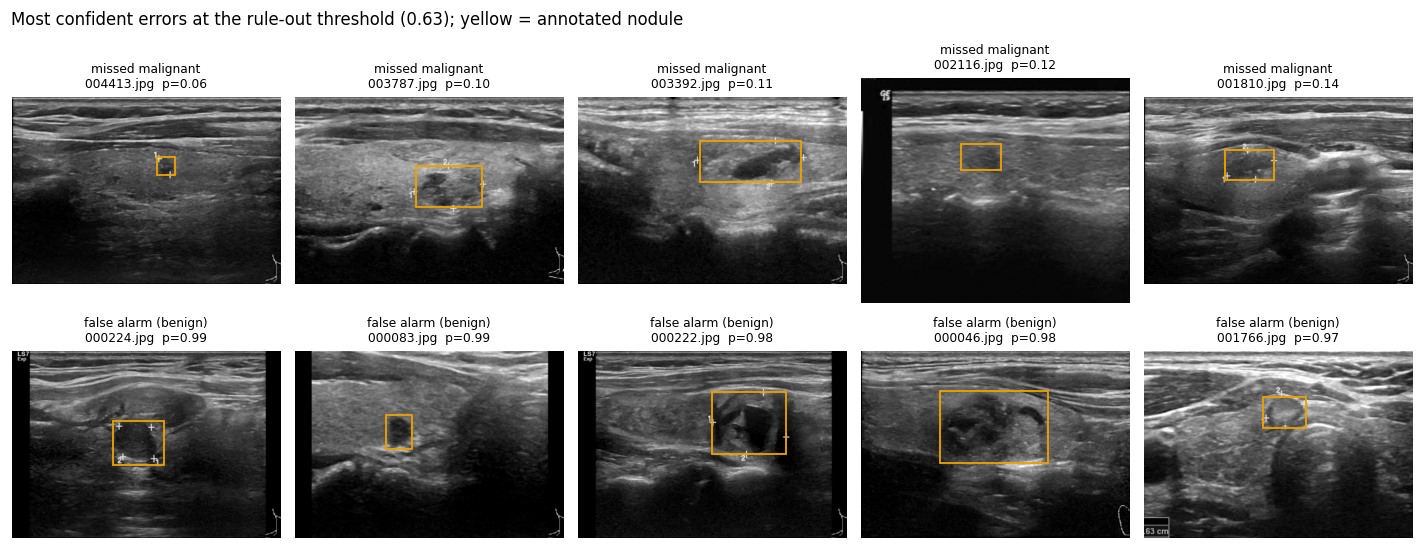

In [24]:
if report and report.get("error_analysis"):
    ea = report["error_analysis"]
    fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
    for r, (key, title) in enumerate((("missed_malignant", "missed malignant"), ("false_alarms", "false alarm (benign)"))):
        for ax, item in zip(axes[r], ea[key][:5]):
            row = tn[tn.file == item["file"]].iloc[0]
            ax.imshow(Image.open(tn5000_root() / "JPEGImages" / item["file"]).convert("L"), cmap="gray")
            ax.add_patch(plt.Rectangle((row.xmin, row.ymin), row.xmax - row.xmin, row.ymax - row.ymin,
                                       fill=False, ec="#eda100", lw=1.2))
            ax.set_title(f"{title}\n{item['file']}  p={item['probability']:.2f}", fontsize=8)
        for ax in axes[r]:
            ax.axis("off")
    fig.suptitle(f"Most confident errors at the rule-out threshold ({ea['threshold']:.2f}); yellow = annotated nodule",
                 x=0.01, ha="left")
    plt.tight_layout()

### Subgroup analysis: nodule size

The confident misses above are mostly small nodules. To check whether that pattern holds beyond five examples,
the test set is split into tertiles by nodule box area (relative to the model's 224x224 input, not physical size)
and evaluated per subgroup with the deployed models' calibration and rule-out threshold.

In [25]:
from sklearn.metrics import roc_auc_score
from training.evaluate import apply_calibration

if report:
    b = data["test_boxes"]
    area = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]) / 224 ** 2
    tertile = np.digitize(area, np.quantile(area, [1 / 3, 2 / 3]))
    rows = []
    for name in ("fibonacci_net", "baseline_cnn"):
        sel = report["models"][name]["selected"]
        pr = np.load(Path("reports/runs") / name / f"seed{sel['seed']}" / "preds.npz")
        pc, y = apply_calibration(pr["p_test"], sel["calibration"]), pr["y_test"]
        for g, label in enumerate(("small", "medium", "large")):
            m = tertile == g
            rows.append({"model": report["models"][name]["display"], "nodule size": label, "images": int(m.sum()),
                         "malignant %": round(100 * y[m].mean(), 1), "AUROC": round(roc_auc_score(y[m], pc[m]), 3),
                         "sensitivity @ rule-out": round((pc[m & (y == 1)] >= sel["thresholds"]["rule_out"]).mean(), 3)})
    display(pd.DataFrame(rows).set_index(["model", "nodule size"]))

images  malignant %  AUROC  \
model                 nodule size                               
FibonacciNet          small           310    57.400002  0.870   
                      medium          309    84.500000  0.880   
                      large           310    76.800003  0.901   
Standard CNN baseline small           310    57.400002  0.886   
                      medium          309    84.500000  0.869   
                      large           310    76.800003  0.873   

                                   sensitivity @ rule-out  
model                 nodule size                          
FibonacciNet          small                         0.764  
                      medium                        0.931  
                      large                         0.924  
Standard CNN baseline small                         0.809  
                      medium                        0.935  
                      large                         0.899

Both models lose sensitivity on the smallest third of nodules. Downscaling the full scanner frame to 224x224 leaves a
small nodule only a few dozen pixels across, losing the fine texture (microcalcifications, margins) that drives
malignancy assessment. A nodule-centred crop at higher resolution is the natural next step.

## 10. Reproducibility

Every run records the code version, data split and environment it was produced with.

In [26]:
if runs_dir.exists():
    prov = []
    for h in sorted(runs_dir.glob("*/seed*/history.json")):
        d = json.loads(h.read_text())
        p = d.get("provenance") or {}
        prov.append({"model": d["model"], "seed": d["seed"], "git commit": p.get("git_commit"),
                     "uncommitted changes": p.get("git_dirty"), "split hash": p.get("splits_sha256"),
                     "train min": round(d["train_seconds"] / 60, 1), "finished": p.get("finished")})
    display(pd.DataFrame(prov).set_index(["model", "seed"]))

git commit  uncommitted changes        split hash  \
model                 seed                                                     
baseline_cnn          0       a0a8087                 True  d2ffaa5c9340d39a   
                      1       a0a8087                 True  d2ffaa5c9340d39a   
                      2       a0a8087                 True  d2ffaa5c9340d39a   
fibonacci_net         0       a0a8087                 True  d2ffaa5c9340d39a   
                      1       a0a8087                 True  d2ffaa5c9340d39a   
                      2       a0a8087                 True  d2ffaa5c9340d39a   
fibonacci_net_pcbnorm 0       a0a8087                 True  d2ffaa5c9340d39a   

                            train min             finished  
model                 seed                                  
baseline_cnn          0          63.2  2026-11-15 08:46:55  
                      1          60.7  2026-11-15 10:21:57  
                      2          60.8  2026-11-15 11:56:54  
fibonacci_net         0          34.5  2026-11-15 07:43:12  
                      1          33.4  2026-11-15 09:20:42  
                      2          33.3  2026-11-15 10:55:36  
fibonacci_net_pcbnorm 0          33.3  2026-11-15 15:26:01

## 11. Limitations

* No patient IDs in either dataset. Perceptual-hash grouping removes near-identical frames but cannot link
  different views of the same patient.
* Kaggle labels are of unknown provenance, so the external result measures transfer to a different, noisier source,
  not performance against a biopsy reference.
* Whole-image classification. The model does not take the nodule location as input, and some frames contain several nodules.
* Single-frame stills: no cine information, Doppler or elastography, and no TI-RADS features as model inputs.
* Lower sensitivity on small nodules: whole-frame downscaling to 224x224 loses fine texture.
* Calibration does not transfer across sites: probabilities calibrated on TN5000 (73% malignant) are miscalibrated on the
  external set (39% malignant) even though discrimination partly transfers. Local recalibration is required before use
  at a new site.
* Research prototype, not a medical device.